In [7]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("../")

import os
from os.path import join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
base_path = "../DATA/"
runsdir = join(base_path,"data/preprocessing/denoising/by_run")
Qiime_dir = [join(runsdir,run) for run in os.listdir(runsdir)]

# Alpha diversity

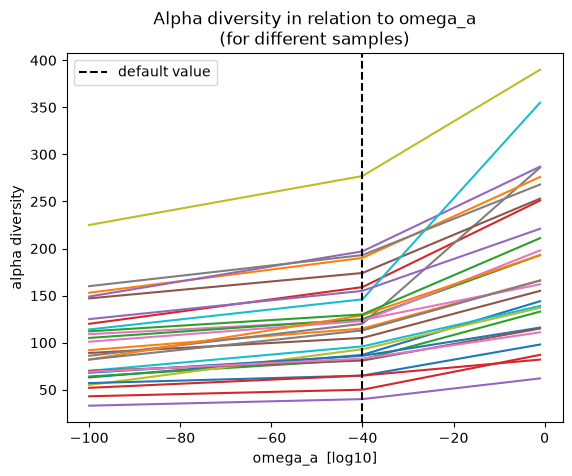

In [9]:
for qiime_dir in Qiime_dir:
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)
        f = (Asv_tab>0).sum(axis=1)
        y = f.values
        x = np.log10(f.index.get_level_values("omega_a"))
        plt.plot(x,y)#,label=qiime_dir.split("/")[-1])

plt.axvline(x=-40,linestyle="--",color="black",label="default value")
plt.title("Alpha diversity in relation to omega_a\n(for different samples)")
plt.xlabel("omega_a  [log10]")
plt.ylabel("alpha diversity")
plt.legend()

# Rank-Abundance

Text(0.5, 0.98, 'Rank-Abundance profile of different samples and omega_a values')

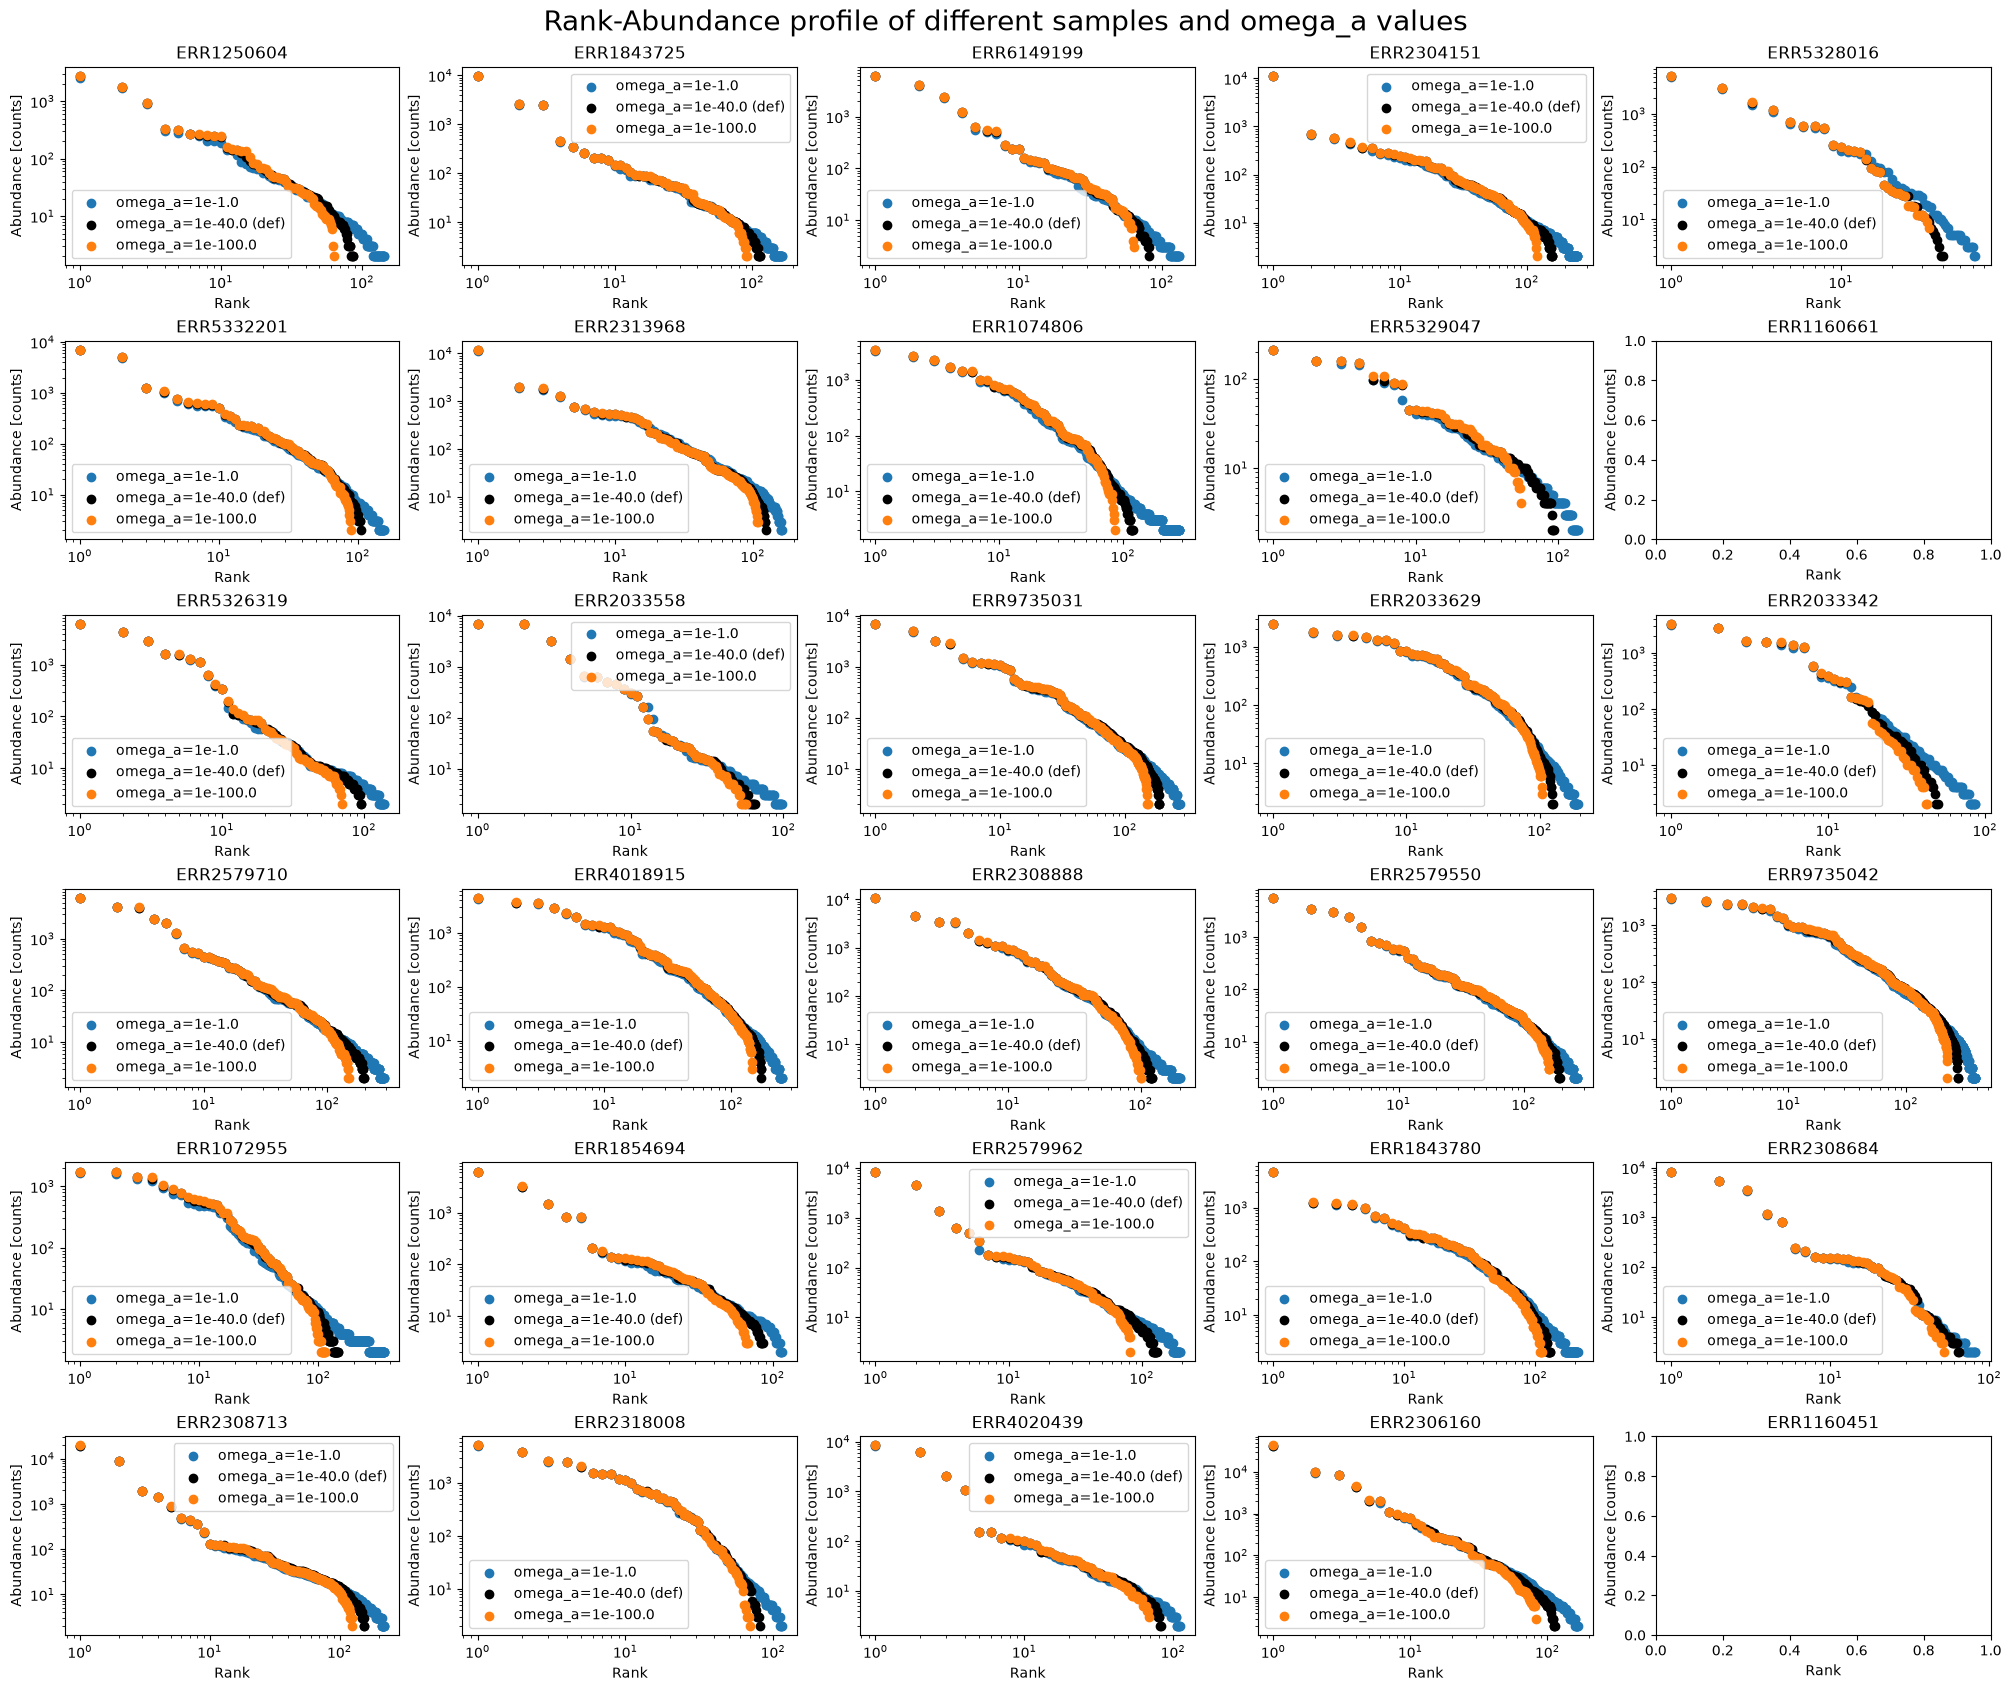

In [78]:
def compute_rank(x,axis=1):
    values = x.values
    ranks  = x.shape[axis]-np.argsort(np.argsort(x,axis=axis),axis=axis)
    return ranks, values

from utils import make_gridplot

fig, axs = make_gridplot(len(Qiime_dir))

for i,(ax,qiime_dir) in enumerate(zip(axs,Qiime_dir)):
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)

        x,y = compute_rank(Asv_tab)

        omega_a = np.log10(Asv_tab.index.get_level_values("omega_a"))
        ax.scatter(x[0 ,:],y[0 ,:],label=f"omega_a=1e{omega_a[ 0]}")
        ax.scatter(x[1 ,:],y[1 ,:],label=f"omega_a=1e{omega_a[ 1]} (def)",color="black")
        ax.scatter(x[-1,:],y[-1,:],label=f"omega_a=1e{omega_a[-1]}")
        ax.loglog()
        ax.legend()

    ax.set_title(qiime_dir.split("/")[-1])
    ax.set_ylabel("Abundance [counts]")
    ax.set_xlabel("Rank")

for j in range(i+1,len(axs)):
    axs[i].set_visible(False)

fig.suptitle("Rank-Abundance profile of different samples and omega_a values",fontsize=20)

# SAD

Text(0.5, 0.98, 'SADs of different samples and omega_a values')

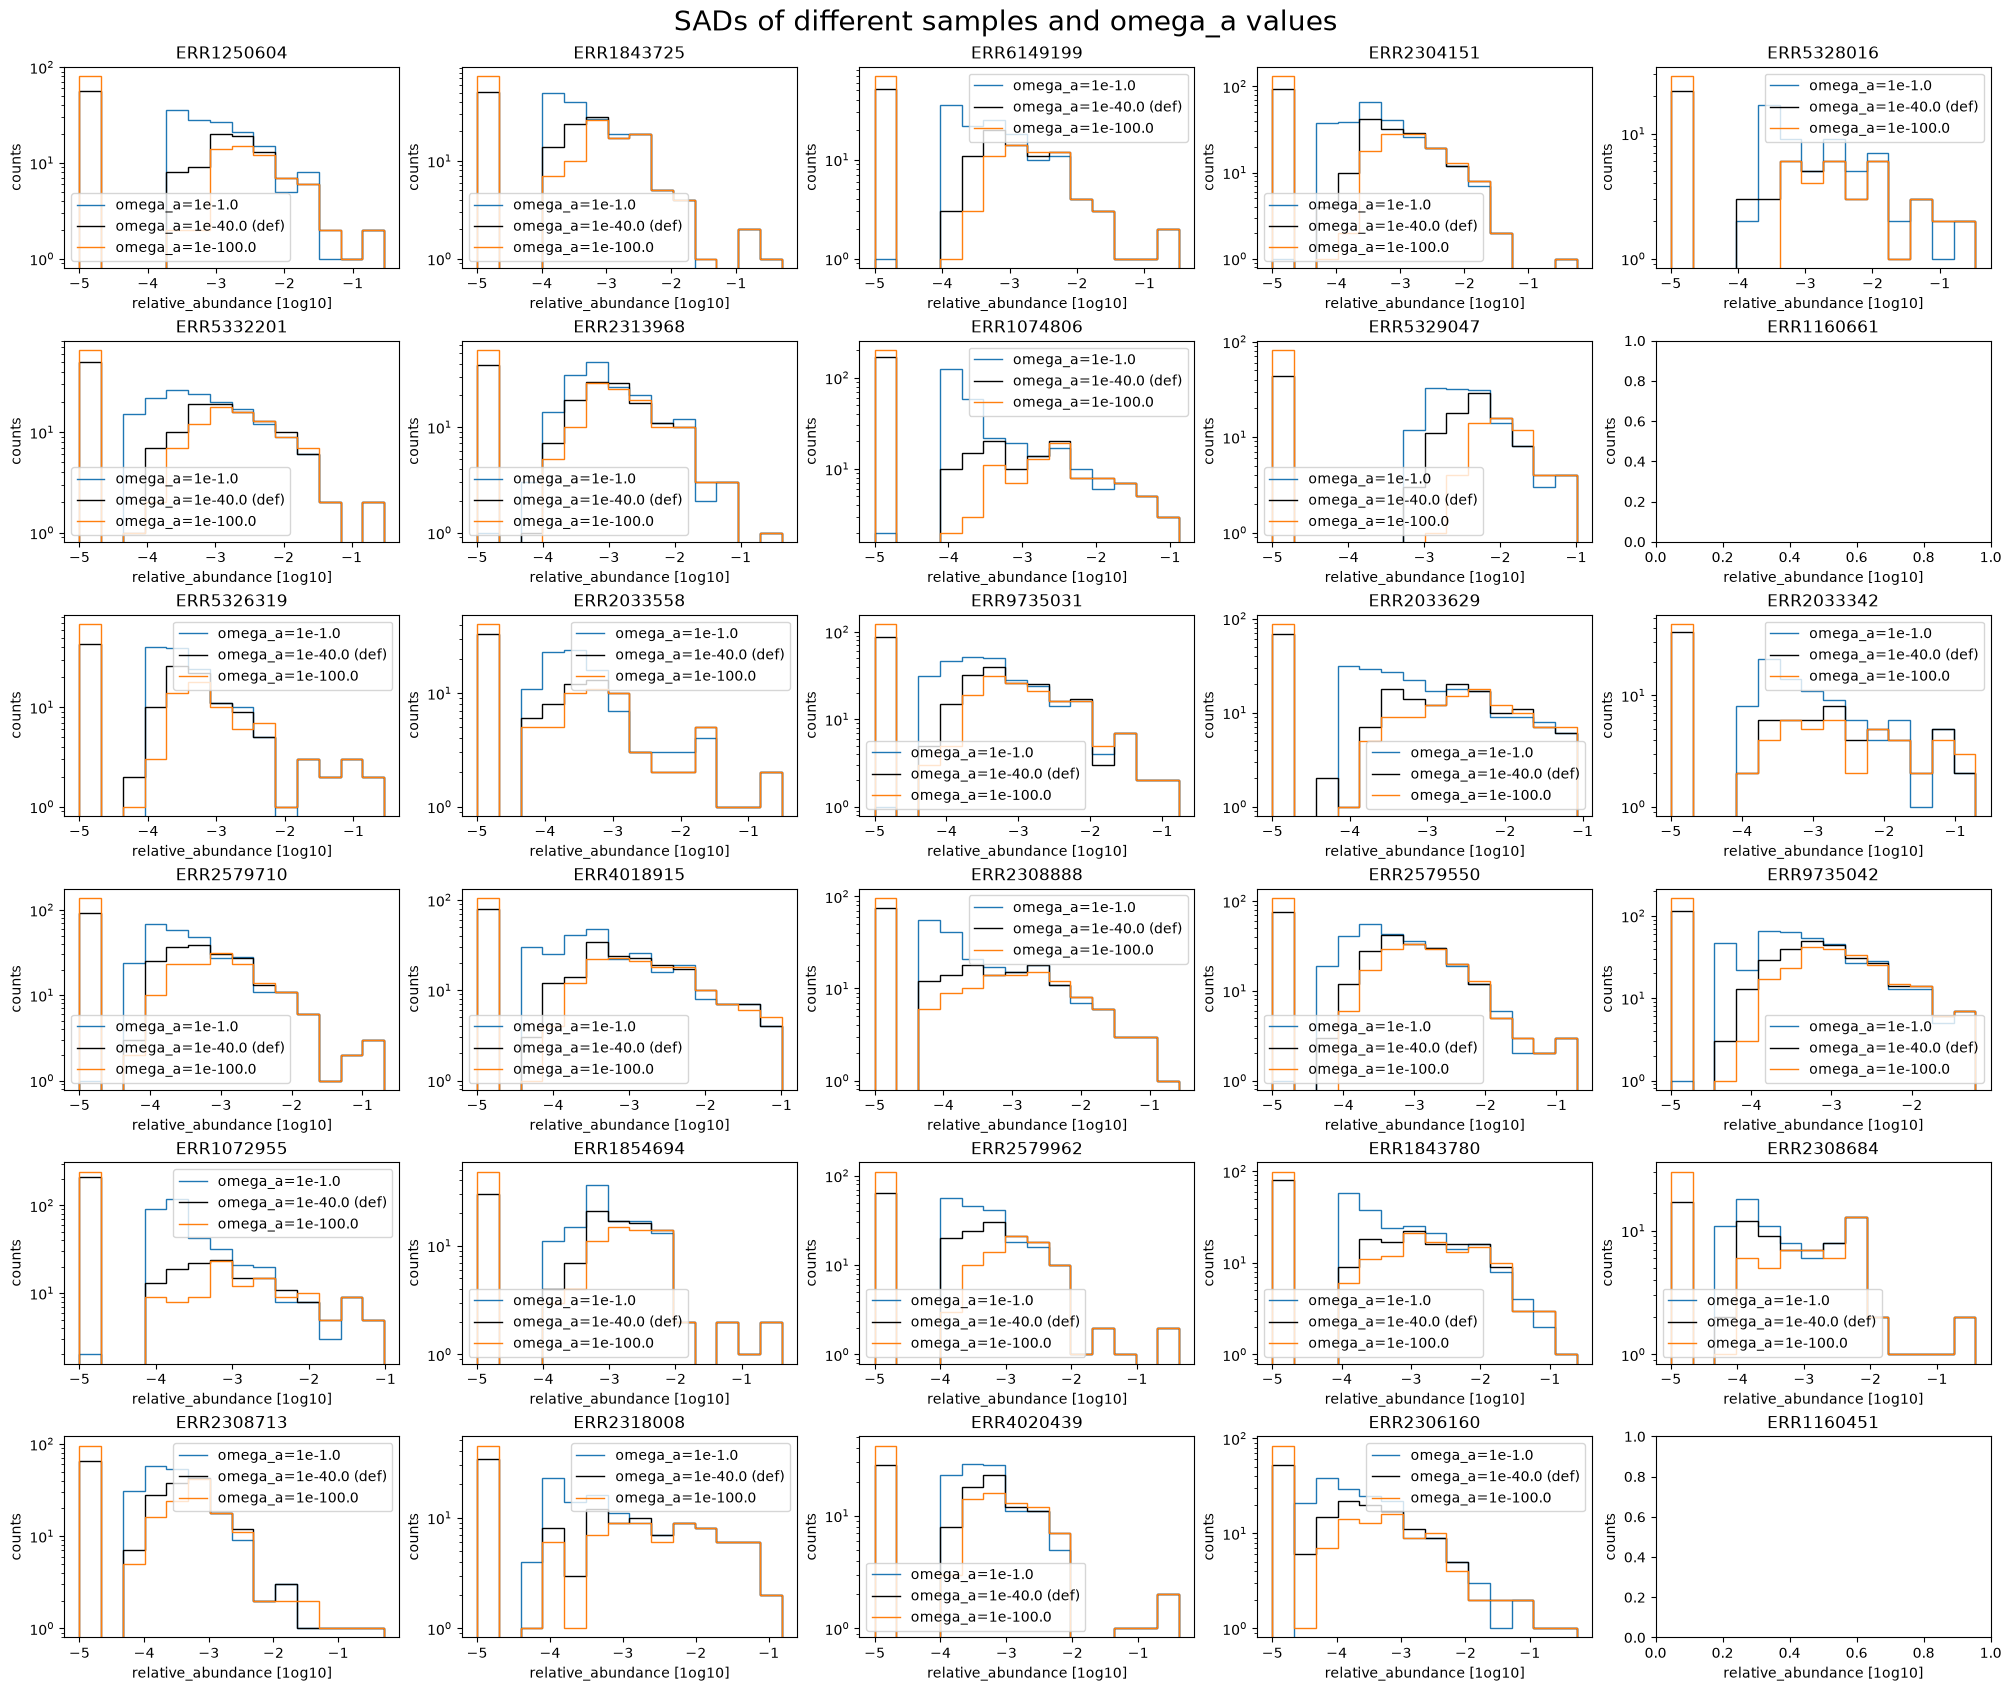

In [79]:
def compute_sad(table,n_bins=10,normalize=True,eps=1e-10,axis=1):
    # prepare input
    if normalize:
        table = table/table.values.sum(axis=axis,keepdims=True) # normalize to relative abundance
    table = np.log10(np.maximum(table,eps))                 # convert to log110, with eps protection for nan
    
    # compute binning
    bins = np.linspace(table.values.ravel().min(),table.values.ravel().max(),n_bins)

    # compute histograms
    counts = np.apply_along_axis(
        lambda col: np.histogram(col, bins=bins)[0],
        axis=axis,
        arr=table
    )
    if axis == 0:
        counts = pd.DataFrame(counts,columns=table.columns)
    if axis == 1:
        counts = pd.DataFrame(counts,index  =table.index  )

    return counts,bins



from utils import make_gridplot

fig, axs = make_gridplot(len(Qiime_dir))

for i,(ax,qiime_dir) in enumerate(zip(axs,Qiime_dir[:])):
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)

        counts,bins = compute_sad(Asv_tab,normalize=True,eps=1e-5,n_bins=15)

        omega_a = np.log10(Asv_tab.index.get_level_values("omega_a"))
        
        ax.stairs(values=counts.values[0,:],edges=bins,label=f"omega_a=1e{omega_a[ 0]}")
        ax.stairs(values=counts.values[1,:],edges=bins,label=f"omega_a=1e{omega_a[ 1]} (def)",color="black")
        ax.stairs(values=counts.values[2,:],edges=bins,label=f"omega_a=1e{omega_a[-1]}")
        ax.set_yscale("log")
        ax.legend()

    ax.set_title(qiime_dir.split("/")[-1])
    ax.set_ylabel("counts")
    ax.set_xlabel("relative_abundance [1og10]")


for j in range(i+1,len(axs)):
    axs[i].set_visible(False)

fig.suptitle("SADs of different samples and omega_a values",fontsize=20)